# phasecast inference, for building an app on it

Four questions, in order: how PyTorch is used, how inputs are formatted,
how the model is loaded, and what to draw. CPU only, runs from the
repository root in seconds. The sampling and drawing code lives beside this
notebook in `inference_helpers.py`; an app calls `predict` and `card` and
never needs to open it.

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "checkpoints").is_dir())
sys.path.insert(0, str(ROOT / "docs" / "tutorial"))
os.chdir(ROOT)  # the heads checkpoint names its encoder by a path relative to the repository root

import json
import pandas as pd
import torch
from inference_helpers import Heads, MAJOR_COLS, TRACE_COLS, card, check_input, predict

# a library module selects matplotlib's file-only backend on import; re-select the notebook backend
%matplotlib inline

torch.set_num_threads(4)

/opt/miniconda3/envs/mineral/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. PyTorch, in full

PyTorch does three things here and nothing else: `torch.load` reads weights
from a file, a module called on a tensor runs a forward pass on CPU, and
`.numpy()` hands the result to numpy. No training, no GPU, no gradients.
Two idioms to know: `eval()` switches off dropout so the same input always
gives the same output, and `torch.no_grad()` skips the bookkeeping that
training would need. Everything after the forward pass is numpy, pandas and
JSON. `set_num_threads` is the one performance knob on a server.

## 2. Input

One row per rock, lowercase columns. Seven major oxides in wt%, iron in any
one of four forms, and up to thirteen trace elements in ppm. A missing value
can be left blank or set to 0; both mean not measured. Nothing else is read.

| columns | unit | required |
|---|---|---|
| `sio2 al2o3 cao mgo k2o na2o tio2` | oxide wt% | yes |
| one of `feo` + `fe2o3`, `feo_tot`, `fe2o3_tot` | oxide wt% | yes |
| `sr_ppm zr_ppm ba_ppm y_ppm rb_ppm ni_ppm nb_ppm v_ppm la_ppm ce_ppm nd_ppm yb_ppm th_ppm` | ppm | no |

Three benchmark rocks stand in for a user's upload; the trachybasalt has its
trace elements withheld to show a majors-only row.

In [2]:
samples = pd.read_csv("data/real_mineralogy/samples.csv", dtype={"sample_id": str}).set_index("sample_id")
DEMO = {"12BA32": "trachybasalt", "203181": "trachyandesite", "203105": "rhyolite"}
rocks = samples.loc[list(DEMO), [*MAJOR_COLS, "feo_tot", *TRACE_COLS]].copy()
rocks.index = pd.Index([f"{name} {sid}" for sid, name in DEMO.items()], name="rock")
rocks.loc[rocks.index[0], TRACE_COLS] = None
rocks.round(2)

,sio2,al2o3,cao,mgo,k2o,na2o,tio2,feo_tot,sr_ppm,zr_ppm,...,y_ppm,rb_ppm,ni_ppm,nb_ppm,v_ppm,la_ppm,ce_ppm,nd_ppm,yb_ppm,th_ppm
rock,,,,,,,,,,,,,,,,,,,,,
trachybasalt 12BA32,49.22,17.02,10.11,7.58,2.27,3.26,1.44,7.97,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
trachyandesite 203181,59.00,16.48,6.15,4.35,3.33,3.68,0.86,5.72,643.0,188.0,...,19.8,142.0,49.0,9.0,133.0,38.7,74.1,35.0,1.6,15.5
rhyolite 203105,66.31,18.32,3.26,1.13,3.39,4.34,0.36,2.60,1150.0,134.0,...,8.4,51.5,6.0,4.0,34.0,24.4,39.6,21.3,0.8,4.8


Validate before predicting. The tokenizer itself does not: an oxide past
100 wt% or a trace past 1,000,000 ppm overflows the encoder's lookup table.
`check_input` returns errors, which refuse a rock, and warnings, which let it
through with a note, every problem at once so a form can show them all.

In [3]:
errors, warnings = check_input(rocks)
print(errors or "no errors", warnings or "no warnings", sep="\n")

no errors
no warnings


Under the hood each row becomes 22 element tokens, an atomic number and a
cation mass fraction per element, with 0 marking an element the row did not
carry. `predict` does this itself; it is shown once so the conversion is not
a mystery.

In [4]:
from cnmineral.data.bulk_chemistry import tokenize_bulk_frame
from cnmineral.data.tokens import VOCAB

src, frac = tokenize_bulk_frame(rocks)
pd.DataFrame([list(src[0]), list(frac[0].round(4))], index=["atomic_number", "cation_mass_fraction"],
             columns=[sym for sym, _ in VOCAB], dtype=object)

,Si,Al,Ca,Mg,Fe,K,Na,Ti,Cr,Sr,...,Y,Rb,Ni,Nb,V,La,Ce,Nd,Yb,Th
atomic_number,14,13,20,12,26,19,11,22,0,0,...,0,0,0,0,0,0,0,0,0,0
cation_mass_fraction,0.2301,0.0901,0.0722,0.0457,0.0619,0.0189,0.0242,0.0086,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 3. Loading

Two files, both tracked in git and both plain `torch.save` dictionaries that
carry their own configuration: the encoder (44 MB, of which 18 MB is weights
and 26 MB optimizer state from pretraining) and the three heads (7 MB), which
record the encoder's path. Loading takes under a tenth of a second.

In [5]:
from cnmineral.eval.latent import load_encoder_from_checkpoint
from cnmineral.training.joint_heads import JointHeadCheckpoint

ckpt = JointHeadCheckpoint.load("checkpoints/joint_heads_allrock_tuned_seed0/heads_best.pt")
encoder, _ = load_encoder_from_checkpoint(ckpt.encoder_checkpoint)
heads = Heads(ckpt.build_mode_head(), ckpt.build_cond_head())

## 4. Predict

`predict` returns one JSON-ready record per rock. Each record carries the
input chemistry, the seven mineral groups the app displays, and the zero-shot
posterior under `posterior`:

| field | shape | meaning |
|---|---|---|
| `presence` | 7 | probability each group is present |
| `share_mean`, `share_p25`, `share_p75` | 7 each | share of the crystalline mass over all samples, percent |
| `scenarios` | up to 5 | distinct mineral lists, each with its probability, mean `share` and `share_p25`, `share_p75` |
| `other_scenarios` | `count`, `prob`, `max_prob` | the mineral lists past the top five |
| `conditions` | 512 each of `T`, `P_kbar`, `H2O` | sampled formation conditions |

Every seven-number array follows the order of `groups`.

In [6]:
records = predict(rocks, encoder, heads)

pd.DataFrame({r["rock"]: r["posterior"]["presence"] for r in records}, index=records[0]["groups"]).T.round(2)

,feldspar,pyroxene,amphibole,biotite,olivine,Fe-Ti oxides,quartz
trachybasalt 12BA32,0.84,1.00,0.86,0.35,0.23,0.34,0.02
trachyandesite 203181,1.00,0.99,0.49,0.71,0.00,0.66,0.50
rhyolite 203105,1.00,0.26,0.16,0.79,0.00,0.88,0.96


## 5. Draw

`card` draws from the record alone. Panels (a) to (c) are the paper's
inference card, Figure 2, without the measured overlay; (d) and (e) are the
two panels of the overview deck's output card.

| panel | record field |
|---|---|
| (a) geochemical input | `input_cation_wt_pct` |
| (b) presence | `posterior["presence"]` |
| (c) abundance | `posterior["share_mean"]`, `share_p25`, `share_p75` |
| (d) possible assemblages | `posterior["scenarios"]`, `posterior["other_scenarios"]` |
| (e) formation conditions | `posterior["conditions"]["T"]`, `["P_kbar"]` |

The conditions panel is a kernel density over the sampled points: the model
gives points, the front end gives the contour (Plotly's 2D density contour
does the same from the raw samples). The pressure axis starts at 0, since the
condition head's Gaussian tails put a few samples just below it. Water content
is in the record under `conditions["H2O"]` and is not drawn.

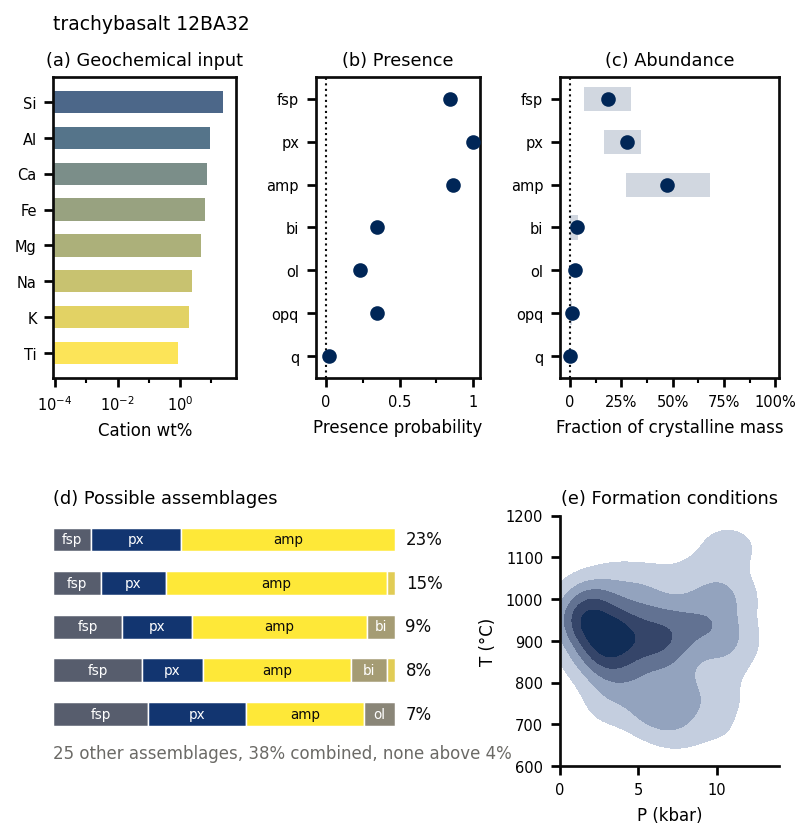

In [7]:
from IPython.display import display
import matplotlib.pyplot as plt

fig = card(records[0])
display(fig)
plt.close(fig)

In [8]:
text = json.dumps(records[0])
print(f"{len(text) / 1024:.0f} KB per rock")
print(text[:300], "...")

10 KB per rock
{"rock": "trachybasalt 12BA32", "input_cation_wt_pct": {"Si": 23.01072, "Al": 9.00782, "Ca": 7.22498, "Mg": 4.57185, "Fe": 6.19378, "K": 1.88664, "Na": 2.41934, "Ti": 0.86141}, "groups": ["feldspar", "pyroxene", "amphibole", "biotite", "olivine", "Fe-Ti oxides", "quartz"], "posterior": {"presence":  ...


## Beyond this notebook

- `README.md` beside this notebook has the setup, timings, dependencies
  and the things that bite.
- The stable inference API (issue #70) promotes `predict` into the package;
  an app imports the library rather than copying the helper file.
- Model internals, if wanted: `docs/encoder.md`, `docs/heads.md`, and the
  deck in `slides/`.